In [75]:
import numpy as np
import skfuzzy as fuzz
from skfuzzy import control as ctrl
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [19]:
####################################################
# INPUTS
####################################################
pm10 = ctrl.Antecedent(np.arange(0, 301, 1), "pm10")
pm25 = ctrl.Antecedent(np.arange(0, 161, 1), "pm25")
wind = ctrl.Antecedent(np.arange(0, 41, 1), "wind")

####################################################
# OUTPUT
####################################################
risk = ctrl.Consequent(np.arange(0, 10.1, 0.1), "environmental_risk")

####################################################
# PM10
####################################################
pm10["good"] = fuzz.zmf(pm10.universe, 10, 20)
pm10["fair"] = fuzz.pimf(pm10.universe, 10, 20, 38, 52)
pm10["moderate"] = fuzz.pimf(pm10.universe, 38, 52, 105, 135)
pm10["poor"] = fuzz.pimf(pm10.universe, 105, 135, 180, 210)
pm10["very_poor"] = fuzz.smf(pm10.universe, 180, 210)

####################################################
# PM25
####################################################
pm25["good"] = fuzz.zmf(pm25.universe, 3, 7)
pm25["fair"] = fuzz.pimf(pm25.universe, 3, 7, 12, 18)
pm25["moderate"] = fuzz.pimf(pm25.universe, 12, 18, 44, 56)
pm25["poor"] = fuzz.pimf(pm25.universe, 44, 56, 82, 98)
pm25["very_poor"] = fuzz.smf(pm25.universe, 82, 98)

####################################################
# WIND
####################################################
wind["low"] = fuzz.trapmf(wind.universe, [0, 0, 6, 12])
wind["medium"] = fuzz.trimf(wind.universe, [8, 18, 28])
wind["high"] = fuzz.trapmf(wind.universe, [22, 30, 40, 40])

####################################################
# OUTPUT
####################################################
risk["very_low"]  = fuzz.trapmf(risk.universe, [0, 0, 1, 2.5])
risk["low"] = fuzz.trimf(risk.universe, [1, 2.5, 4.5])
risk["medium"] = fuzz.trimf(risk.universe, [3.5, 5, 6.5])
risk["high"] = fuzz.trimf(risk.universe, [5.5, 7.5, 9])
risk["very_high"] = fuzz.trapmf(risk.universe, [7.5, 9, 10, 10])
####################################################
# RULES
####################################################
# Orden de severidad de las etiquetas de contaminación
NIVELES_PM = ["good", "fair", "moderate", "poor", "very_poor"]
 
# Nivel de riesgo correspondiente a cada índice de severidad
NIVELES_RIESGO = ["very_low", "low", "medium", "high", "very_high"]
 
# Ajuste que introduce el viento sobre el nivel base
AJUSTE_VIENTO = {
    "low":     +1, # calma: menor dispersión, se agrava el nivel
    "medium":   0, # condiciones neutras
    "high":    -1, # viento intenso: mayor dispersión, se relaja
}
 
 
def _nivel_resultante(idx_pm10, idx_pm25, etiqueta_viento):
    """Determina la etiqueta de salida para una combinación de entradas.
 
    El nivel base lo fija el peor de los dos contaminantes, siguiendo el
    criterio del índice europeo de calidad del aire. El viento lo ajusta
    en un escalón, acotado al rango disponible.
    """
    base = max(idx_pm10, idx_pm25)
    ajustado = base + AJUSTE_VIENTO[etiqueta_viento]
    ajustado = max(0, min(len(NIVELES_RIESGO) - 1, ajustado))
    return NIVELES_RIESGO[ajustado]
 
 
def _construir_reglas():
    reglas = []
    for i, et_pm10 in enumerate(NIVELES_PM):
        for j, et_pm25 in enumerate(NIVELES_PM):
            for et_wind in AJUSTE_VIENTO:
                salida = _nivel_resultante(i, j, et_wind)
                reglas.append(
                    ctrl.Rule(
                        pm10[et_pm10] & pm25[et_pm25] & wind[et_wind],
                        risk[salida],
                    )
                )
    return reglas
 
 
rules = _construir_reglas()
 
 
####################################################
# CONTROL SYSTEM
####################################################
fis = ctrl.ControlSystem(rules)
simulation = ctrl.ControlSystemSimulation(fis)

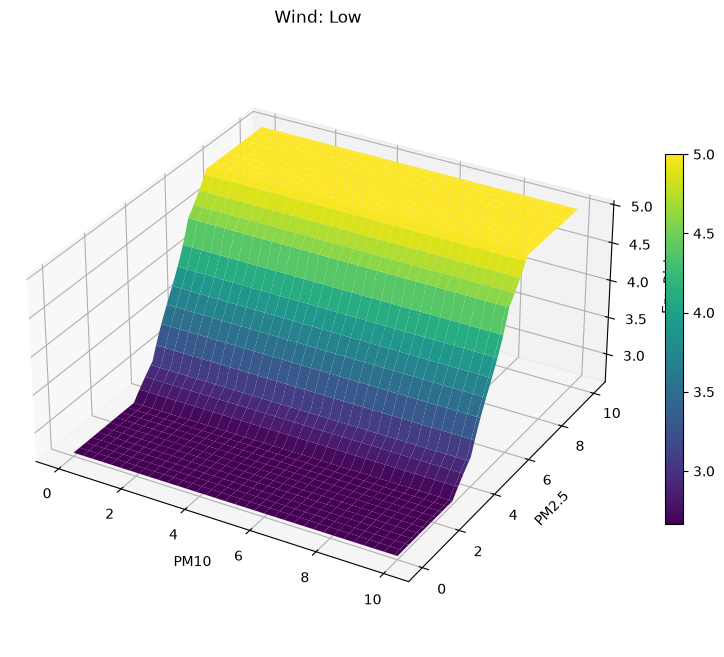

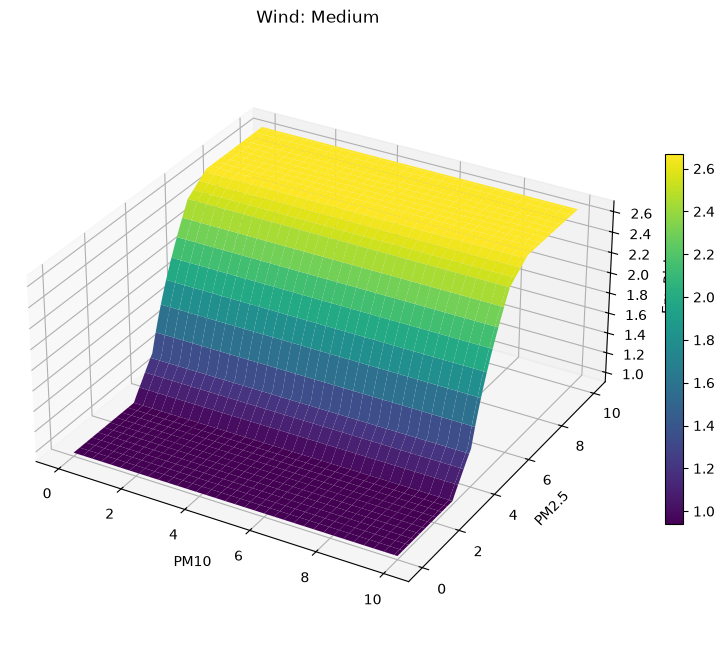

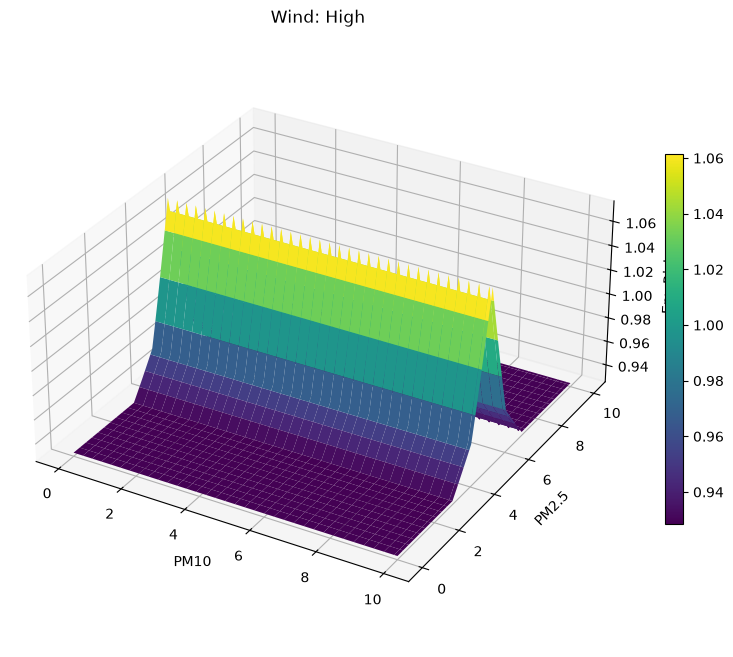

In [ ]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

def plot_surface(wind_inp, title):

    pm10_range = np.linspace(0, 10, 101)
    pm25_range = np.linspace(0, 10, 101)

    PM10, PM25 = np.meshgrid(pm10_range, pm25_range)

    OUTPUT = np.zeros_like(PM10)

    for i in range(PM10.shape[0]):
        for j in range(PM10.shape[1]):

            sim = ctrl.ControlSystemSimulation(fis)

            sim.input["pm10"] = PM10[i, j]
            sim.input["pm25"] = PM25[i, j]
            sim.input["wind"] = wind_inp

            sim.compute()

            OUTPUT[i, j] = sim.output["environmental_risk"]

    fig = plt.figure(figsize=(10, 8))
    ax = fig.add_subplot(111, projection="3d")

    surface = ax.plot_surface(
        PM10,
        PM25,
        OUTPUT,
        cmap="viridis",
        edgecolor="none",
        antialiased=True
    )

    ax.set_xlabel("PM10")
    ax.set_ylabel("PM2.5")
    ax.set_zlabel("Env Risk")
    ax.set_title(title)
    ax.set_box_aspect((1,1,0.5))

    fig.colorbar(surface, shrink=0.6)

    plt.show()

plot_surface(0, "Wind: Low")
plot_surface(17.5, "Wind: Medium")
plot_surface(10, "Wind: High")

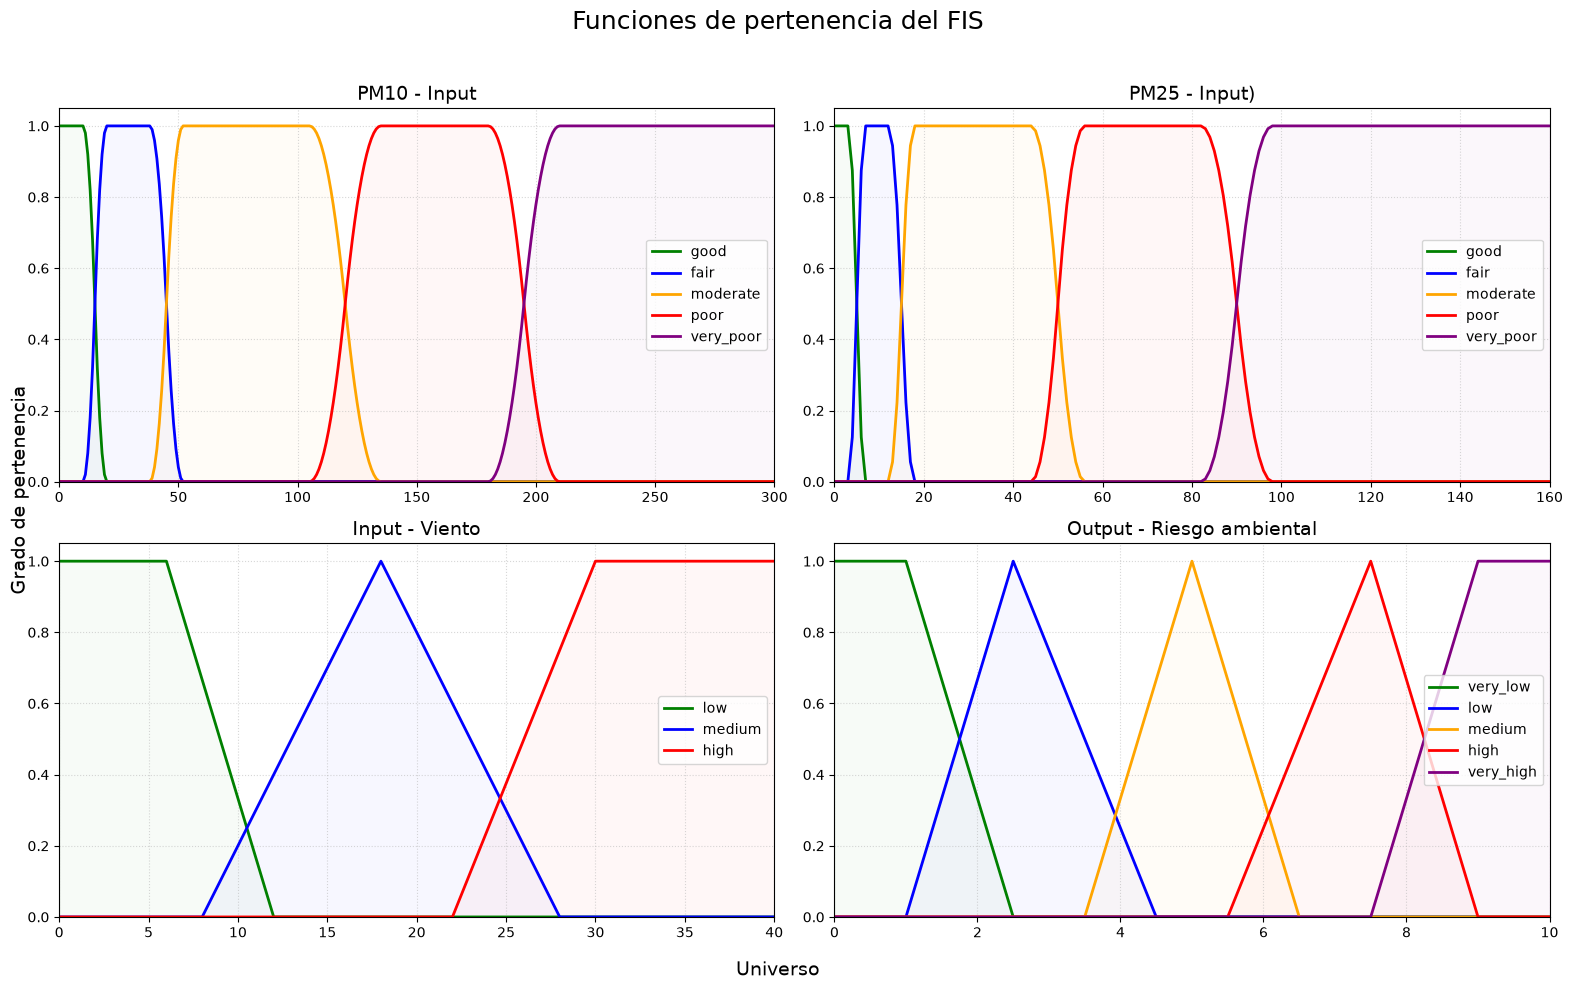

In [21]:
fig, axes = plt.subplots(
    2, 2,
    figsize=(16, 10)
)

# Colores utilizados
colors_5 = [
    "green",
    "blue",
    "orange",
    "red",
    "purple"
]

colors_3 = [
    "green",
    "blue",
    "red"
]


# PM10
ax = axes[0, 0]

for color, label in zip(colors_5, pm10.terms):
    
    ax.plot(
        pm10.universe,
        pm10[label].mf,
        color=color,
        linewidth=2,
        label=label
    )

    ax.fill_between(
        pm10.universe,
        0,
        pm10[label].mf,
        color=color,
        alpha=0.03
    )

ax.set_title(
    "PM10 - Input",
    fontsize=14,
)

ax.set_xlim(0, 300)
ax.set_ylim(0, 1.05)

ax.grid(
    True,
    linestyle=":",
    alpha=0.5
)

ax.legend(
    loc="center right",
    frameon=True
)


# PM2.5
ax = axes[0, 1]

for color, label in zip(colors_5, pm25.terms):

    ax.plot(
        pm25.universe,
        pm25[label].mf,
        color=color,
        linewidth=2,
        label=label
    )

    ax.fill_between(
        pm25.universe,
        0,
        pm25[label].mf,
        color=color,
        alpha=0.03
    )

ax.set_title(
    "PM25 - Input)",
    fontsize=14,
)

ax.set_xlim(0, 160)
ax.set_ylim(0, 1.05)

ax.grid(
    True,
    linestyle=":",
    alpha=0.5
)

ax.legend(
    loc="center right",
    frameon=True
)


# VIENTO
ax = axes[1, 0]

for color, label in zip(colors_3, wind.terms):

    ax.plot(
        wind.universe,
        wind[label].mf,
        color=color,
        linewidth=2,
        label=label
    )

    ax.fill_between(
        wind.universe,
        0,
        wind[label].mf,
        color=color,
        alpha=0.03
    )

ax.set_title(
    "Input - Viento",
    fontsize=14,
)

ax.set_xlim(0, 40)
ax.set_ylim(0, 1.05)

ax.grid(
    True,
    linestyle=":",
    alpha=0.5
)

ax.legend(
    loc="center right",
    frameon=True
)


# RIESGO AMBIENTAL
ax = axes[1, 1]

for color, label in zip(colors_5, risk.terms):

    ax.plot(
        risk.universe,
        risk[label].mf,
        color=color,
        linewidth=2,
        label=label
    )

    ax.fill_between(
        risk.universe,
        0,
        risk[label].mf,
        color=color,
        alpha=0.03
    )

ax.set_title(
    "Output - Riesgo ambiental",
    fontsize=14,
)


ax.set_xlim(0, 10)
ax.set_ylim(0, 1.05)

ax.grid(
    True,
    linestyle=":",
    alpha=0.5
)

ax.legend(
    loc="center right",
    frameon=True
)


# CONFIGURACIÓN FINAL

plt.suptitle(
    "Funciones de pertenencia del FIS",
    fontsize=18,
)

fig.supxlabel(
    "Universo",
    fontsize=14
)

fig.supylabel(
    "Grado de pertenencia",
    fontsize=14
)
plt.tight_layout(
    rect=[0, 0, 1, 0.96]
)

plt.show()



In [ ]:
def clasificar_pm25(valor):
    if valor <= 5:
        return "Good"
    elif valor <= 15:
        return "Fair"
    elif valor <= 50:
        return "Moderate"
    elif valor <= 90:
        return "Poor"
    elif valor <= 140:
        return "Very poor"
    else:
        return "Very poor"

def clasificar_pm10(valor):
    if valor <= 15:
        return "Good"
    elif valor <= 45:
        return "Fair"
    elif valor <= 120:
        return "Moderate"
    elif valor <= 195:
        return "Poor"
    elif valor <= 270:
        return "Very poor"
    else:
        return "Very poor"

df_historico = pd.read_csv("requests-and-examples-for-testing/data/rvvcca_d_horarios_2021-2022.csv",sep=";", index_col=False)[["PM2.5","PM10"]].dropna()

In [ ]:
df_historico["PM10_EAQI"] = df_historico["PM10"].apply(clasificar_pm10)
df_historico["PM25_EAQI"] = df_historico["PM2.5"].apply(clasificar_pm25)

niveles = {
    "Good": 0,
    "Fair": 1,
    "Moderate": 2,
    "Poor": 3,
    "Very poor": 4,
    "Very poor": 5
}

df_historico["PM2.5_level"] = df_historico["PM25_EAQI"].map(niveles)
df_historico["PM10_level"] = df_historico["PM10_EAQI"].map(niveles)

df_historico["EAQI_level"] = df_historico[
    ["PM2.5_level", "PM10_level"]
].max(axis=1)
niveles_inverso = {v: k for k, v in niveles.items()}

df_historico["EAQI_label"] = df_historico["EAQI_level"].map(niveles_inverso)
niveles_inverso = {v: k for k, v in niveles.items()}

df_historico["EAQI_label"] = df_historico["EAQI_level"].map(niveles_inverso)

In [25]:
def obtener_salida_fis(pm25, pm10, wind):

    simulation.input["pm25"] = pm25
    simulation.input["pm10"] = pm10
    simulation.input["wind"] = wind

    simulation.compute()

    return simulation.output["environmental_risk"]


df_historico["FIS_wind_0"] = df_historico.apply(
    lambda row: obtener_salida_fis(row["PM2.5"], row["PM10"], 0),
    axis=1
)

df_historico["FIS_wind_17.5"] = df_historico.apply(
    lambda row: obtener_salida_fis(row["PM2.5"], row["PM10"], 17.5),
    axis=1
)

df_historico["FIS_wind_40"] = df_historico.apply(
    lambda row: obtener_salida_fis(row["PM2.5"], row["PM10"], 40),
    axis=1
)

In [26]:
df_historico.to_csv("requests-and-examples-for-testing/data/historico-con-FIS-EAQI.csv", sep=";")

In [56]:
df_historico = pd.read_csv("requests-and-examples-for-testing/data/historico-con-FIS-EAQI.csv",sep=";").drop(columns="Unnamed: 0")
df_historico

,PM2.5,PM10,PM10_EAQI,PM25_EAQI,PM2.5_level,PM10_level,EAQI_level,EAQI_label,FIS_wind_0,FIS_wind_17.5,FIS_wind_40
0,11.0,20.0,Fair,Fair,1,1,1,Fair,5.000000,2.667063,0.928571
1,24.0,48.0,Moderate,Moderate,2,2,2,Moderate,7.329514,5.000000,2.670486
2,19.0,39.0,Fair,Moderate,2,1,2,Moderate,7.333316,5.000000,2.666684
3,11.0,26.0,Fair,Fair,1,1,1,Fair,5.000000,2.667063,0.928571
4,21.0,36.0,Fair,Moderate,2,1,2,Moderate,7.333333,5.000000,2.666667
...,...,...,...,...,...,...,...,...,...,...,...
120659,8.0,12.0,Good,Fair,1,0,1,Fair,5.000000,2.667654,0.948840
120660,9.0,18.0,Fair,Fair,1,1,1,Fair,5.000000,2.667654,0.948840
120661,12.0,36.0,Fair,Fair,1,1,1,Fair,5.000000,2.667063,0.928571
120662,9.0,20.0,Fair,Fair,1,1,1,Fair,5.000000,2.667063,0.928571


In [ ]:
def obtener_etiqueta_fis(valor):
    
    pertenencias = {
        "very_low": fuzz.interp_membership(
            risk.universe,
            risk["very_low"].mf,
            valor
        ),
        "low": fuzz.interp_membership(
            risk.universe,
            risk["low"].mf,
            valor
        ),
        "medium": fuzz.interp_membership(
            risk.universe,
            risk["medium"].mf,
            valor
        ),
        "high": fuzz.interp_membership(
            risk.universe,
            risk["high"].mf,
            valor
        ),
        "very_high": fuzz.interp_membership(
            risk.universe,
            risk["very_high"].mf,
            valor
        )
    }

    return max(pertenencias, key=pertenencias.get)

etiquetas_fis = {
    "very_low": "Good",
    "low": "Fair",
    "medium": "Moderate",
    "high": "Poor",
    "very_high": "Very poor"
}


df_historico["FIS_wind_0_label"] = df_historico["FIS_wind_0"].apply(
    lambda x: etiquetas_fis[obtener_etiqueta_fis(x)]
)

df_historico["FIS_wind_17.5_label"] = df_historico["FIS_wind_17.5"].apply(
    lambda x: etiquetas_fis[obtener_etiqueta_fis(x)]
)

df_historico["FIS_wind_40_label"] = df_historico["FIS_wind_40"].apply(
    lambda x: etiquetas_fis[obtener_etiqueta_fis(x)]
)

In [58]:
df_historico["check_wind0"] = df_historico["FIS_wind_0_label"] == df_historico["EAQI_label"]
df_historico["check_wind17"] = df_historico["FIS_wind_17.5_label"] == df_historico["EAQI_label"]
df_historico["check_wind40"] = df_historico["FIS_wind_40_label"] == df_historico["EAQI_label"]

In [59]:
df_historico["check_wind0"].value_counts()

check_wind0
False    120586
True         78
Name: count, dtype: int64

In [60]:
df_historico["check_wind17"].value_counts()


check_wind17
True     113225
False      7439
Name: count, dtype: int64

In [61]:
df_historico["check_wind40"].value_counts()


check_wind40
False    86580
True     34084
Name: count, dtype: int64

In [69]:
matriz_0 = pd.crosstab(
    df_historico["EAQI_label"],
    df_historico["FIS_wind_0_label"],
    normalize="index"
).round(3) * 100

In [70]:
matriz_17 = pd.crosstab(
    df_historico["EAQI_label"],
    df_historico["FIS_wind_17.5_label"],
    normalize="index"
).round(3) * 100

In [71]:
matriz_40 = pd.crosstab(
    df_historico["EAQI_label"],
    df_historico["FIS_wind_40_label"],
    normalize="index"
).round(3) * 100

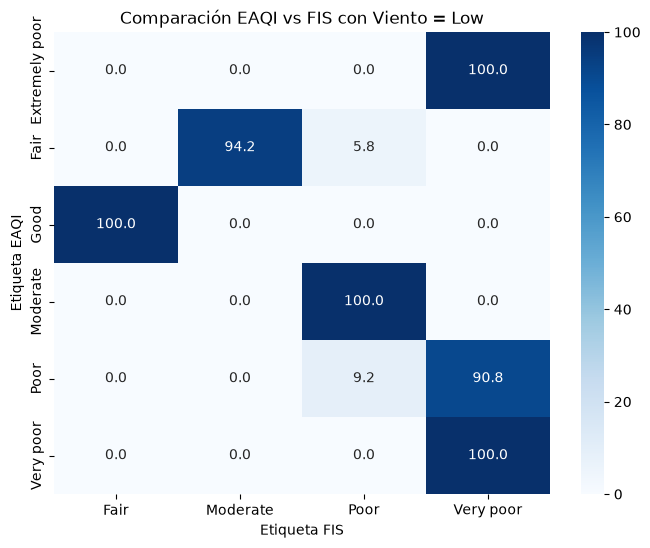

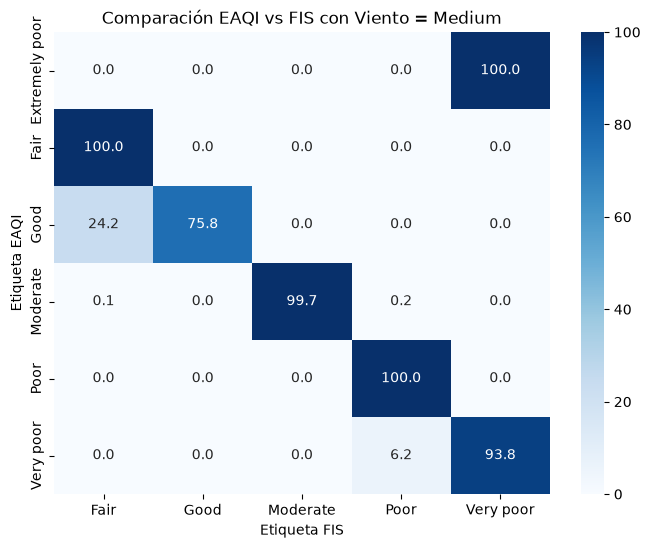

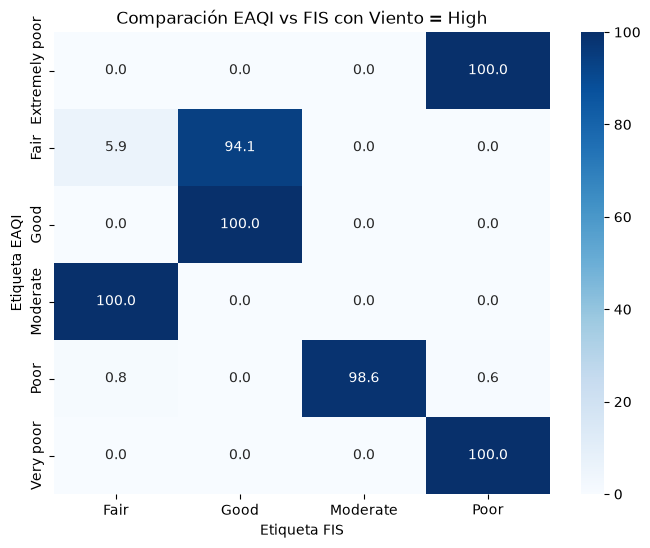

In [78]:
matrices = [matriz_0, matriz_17, matriz_40]
iteraciones = ["Low", "Medium", "High"]

for matriz, viento in zip(matrices, iteraciones):

    plt.figure(figsize=(8, 6))

    sns.heatmap(
        matriz,
        annot=True,
        fmt=".1f",
        cmap="Blues"
    )

    plt.xlabel("Etiqueta FIS")
    plt.ylabel("Etiqueta EAQI")
    plt.title(f"Comparación EAQI vs FIS con Viento = {viento}")

    plt.show()